# retina-09-demo-pack

**Builds everything the final demo needs, after checking the offline script against the real model.**

**Settings:** Accelerator **None** · Internet **Off** · about 5–10 minutes.

**Add Data (3):** `retina-deployable` · `retina-generalisation` · `retina-external-512`

**Save Version → Save & Run All**, as for the other notebooks. No edits needed. When it finishes, open the version's **Output** tab and download **`demo_pack.zip`**, then download the executed notebook for the repo (commit 12 in the guide). Nothing needs publishing as a dataset.

| Cell | What it does |
|---|---|
| 1 | Finds the three inputs; stops if one is missing |
| 2–3 | Writes the fixed `infer_offline.py` and the degradation code, identical to `deploy/infer_offline.py` and `src/data/degrade.py` in the repo |
| 4 | Runs the script on 400 external photographs and compares its verdicts with the validated predictions. **Stops if they agree on fewer than 95%** |
| 5 | Picks the demo photographs, keeping only those where the script says what the demo needs |
| 6 | Builds the pack, runs the script exactly as the laptop will, and saves what it printed as `EXPECTED.txt` |
| 7 | Lists the outputs |

Section 5 of the commit guide describes the same steps.

In [1]:
# ============================================================================
# CELL 1 - Inputs. Stops here if a dataset is missing, not ten minutes in.
# ============================================================================
# Settings: Accelerator None, Internet Off.
# Add Data: retina-deployable, retina-generalisation, retina-external-512.
import shutil
import subprocess
import sys
import time
import zipfile
from datetime import date
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working")


def find_file(name):
    hits = sorted(INPUT.rglob(name))
    if not hits:
        raise FileNotFoundError(
            f"'{name}' not found under {INPUT}. Add Data: retina-deployable, "
            "retina-generalisation, retina-external-512")
    return hits[0]


MODEL = find_file("retina_multihead_float16.tflite")
REF_CSV = find_file("predictions_external.csv")
MANIFEST = find_file("manifest_external_512.csv")
IMAGES = MANIFEST.parent / "external_512"
if not IMAGES.is_dir():
    raise FileNotFoundError(f"{IMAGES} is missing - attach the whole retina-external-512 dataset")

ref = pd.read_csv(REF_CSV)
for col in ["dr_grade", "clarity"]:
    ref[col] = pd.to_numeric(ref[col], errors="coerce") if col in ref else np.nan
SEV_COLS = [c for c in ref.columns if c.startswith("sev_")]
assert len(SEV_COLS) == 4, f"expected four sev_ columns in predictions_external.csv, found {SEV_COLS}"

print(f"model        {MODEL}  ({MODEL.stat().st_size / 1e6:.2f} MB)")
print(f"predictions  {REF_CSV}  ({len(ref):,} rows)")
print(f"images       {IMAGES}")
print("\n" + ref.dataset.value_counts().to_string())

model        /kaggle/input/datasets/izuchukwuoruche/retina-deployable/tflite/retina_multihead_float16.tflite  (8.74 MB)
predictions  /kaggle/input/datasets/izuchukwuoruche/retina-generalisation/predictions_external.csv  (4,556 rows)
images       /kaggle/input/datasets/izuchukwuoruche/retina-external-512/external_512

dataset
fqs         2246
deepdrid    1600
idrid        516
drimdb       194


In [2]:
%%writefile /kaggle/working/infer_offline.py
"""Offline gradability check for retinal photographs. No network, no GPU.

    pip install -r requirements-deploy.txt
    python infer_offline.py photo1.jpg [photo2.jpg ...]

Needs retina_multihead_float16.tflite next to this file (download it from the
`retina-deployable` Kaggle dataset, tflite/ folder), or pass --model PATH.

For each photograph it prints a verdict (Good / Usable / Reject), the model's
confidence, the most likely defect when the verdict is not Good, and a one-line
retake instruction for the operator.

How this differs from the file retina-08-compression wrote
-----------------------------------------------------------
That version resized the photograph straight to 224 x 224 with bilinear
interpolation. The model was trained and validated on images that had first been
cropped to the retina, padded to a square and area-resized to 512 px, and then
area-resized to 224. Skipping those steps squashes a rectangular camera frame into a
square and changes the resampling - and this model is, among other things, a blur
detector. prepare() below repeats the training pipeline step for step, using the same
OpenCV calls as src/data/preprocess.py. This was found when the code was archived;
deploy/check_against_reference.py measures the agreement in Kaggle.
"""
import argparse
import sys
from pathlib import Path

import cv2
import numpy as np

STORE_SIZE = 512      # every training image was stored at 512 x 512
SIZE = 224            # what the model sees
CLASSES = ["Good", "Usable", "Reject"]
DEFECTS = ["underexposed", "defocus", "obstruction", "off_centre"]
DEFAULT_MODEL = Path(__file__).resolve().parent / "retina_multihead_float16.tflite"

# The defect head was trained on severities of 0 (absent) or 0.25-1.0 (present),
# so 0.25 is the smallest value that means "this defect is there".
PRESENT = 0.25

RETAKE = {
    "underexposed": "Too dark. Check pupil size and flash, then retake.",
    "defocus": "Blurred. Refocus and ask the patient to keep still, then retake.",
    "obstruction": "Eyelid or lashes in the way. Ask the patient to open wide, then retake.",
    "off_centre": "Off centre. Re-align on the optic disc and macula, then retake.",
}
NO_CAMERA_CAUSE = ("No camera defect stands out, so the eye itself may be the cause "
                   "(for example a cataract). Retake once; if it is still rejected, "
                   "send it on for the grader to judge.")


# ---- preprocessing: identical to src/data/preprocess.py ------------------------
def crop_fov(img, tol=7):
    """Trim the black surround around the circular field of view."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    mask = gray > tol
    if not mask.any():
        return img
    ys, xs = np.where(mask)
    return img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]


def pad_square(img):
    """Pad the short side so resizing does not distort the retina."""
    h, w = img.shape[:2]
    s = max(h, w)
    t, l = (s - h) // 2, (s - w) // 2
    return cv2.copyMakeBorder(img, t, s - h - t, l, s - w - l,
                              cv2.BORDER_CONSTANT, value=[0, 0, 0])


def prepare(path):
    """Photograph on disk -> model input, exactly as in training.

    1. crop to the retina, pad to square, area-resize to 512 (as every dataset was)
    2. area-resize 512 -> 224 in float32 (training used tf.image.resize "area")
    Returns float32 [1, 224, 224, 3] in [0, 255] - NOT normalised; EfficientNet
    rescales internally.
    """
    img = cv2.imread(str(path))                      # BGR uint8, like every notebook
    if img is None:
        raise ValueError(f"cannot read image: {path}")
    stored = cv2.resize(pad_square(crop_fov(img)), (STORE_SIZE, STORE_SIZE),
                        interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(stored, cv2.COLOR_BGR2RGB).astype(np.float32)
    x = cv2.resize(rgb, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    return x[None]


# ---- the model -----------------------------------------------------------------
def _interpreter_class():
    """LiteRT if installed, then the older tflite-runtime, then full TensorFlow.

    The TensorFlow fallback must be attribute access. The version retina-08 wrote
    used `from tensorflow.lite import Interpreter`, which raises ImportError on
    TensorFlow 2.20 because tensorflow.lite is loaded lazily - and tflite-runtime has
    no builds for Python 3.12+, so on a current laptop that script could not start.
    """
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        try:
            from tflite_runtime.interpreter import Interpreter
        except ImportError:
            import tensorflow as tf
            Interpreter = tf.lite.Interpreter
    return Interpreter


class Assessor:
    def __init__(self, model_path=DEFAULT_MODEL):
        model_path = Path(model_path)
        if not model_path.exists():
            raise FileNotFoundError(
                f"{model_path} not found - download it from the retina-deployable "
                f"Kaggle dataset (tflite/ folder) and put it next to this script")
        self.it = _interpreter_class()(model_path=str(model_path))
        self.it.resize_tensor_input(self.it.get_input_details()[0]["index"],
                                    [1, SIZE, SIZE, 3])
        self.it.allocate_tensors()
        self.inp = self.it.get_input_details()[0]["index"]
        # Identify the two heads by SHAPE. TFLite output names are opaque and their
        # order is not guaranteed; reading them by position would silently swap
        # gradability for defects.
        by_units = {int(d["shape"][-1]): d["index"]
                    for d in self.it.get_output_details()}
        if 3 not in by_units or len(DEFECTS) not in by_units:
            raise RuntimeError(f"unexpected model outputs: {by_units}")
        self.grad, self.defects = by_units[3], by_units[len(DEFECTS)]

    def assess(self, path):
        """Returns (verdict, confidence, {defect: severity})."""
        self.it.set_tensor(self.inp, prepare(path))
        self.it.invoke()
        g = self.it.get_tensor(self.grad)[0]
        d = self.it.get_tensor(self.defects)[0]
        return CLASSES[int(g.argmax())], float(g.max()), dict(zip(DEFECTS, d.tolist()))


def advice(verdict, defects):
    """One line for the operator."""
    if verdict == "Good":
        return "Gradable. No retake needed."
    worst = max(defects, key=defects.get)
    cause = RETAKE[worst] if defects[worst] >= PRESENT else NO_CAMERA_CAUSE
    if verdict == "Usable":
        return "Gradable, but borderline. If the patient is still here: " + cause
    return "Not gradable. " + cause


def main(argv=None):
    ap = argparse.ArgumentParser(description="Offline retinal gradability check")
    ap.add_argument("images", nargs="+", help="photograph(s) to check")
    ap.add_argument("--model", default=str(DEFAULT_MODEL), help="path to the .tflite")
    args = ap.parse_args(argv)

    assessor = Assessor(args.model)
    for p in args.images:
        try:
            verdict, conf, defects = assessor.assess(p)
        except ValueError as e:
            print(f"{p}: {e}")
            continue
        print(f"{p}: {verdict}  ({conf:.0%} confident)")
        if verdict != "Good":
            worst = max(defects, key=defects.get)
            print(f"  most likely cause: {worst}  (severity {defects[worst]:.2f})")
        print(f"  {advice(verdict, defects)}")
    return 0


if __name__ == "__main__":
    sys.exit(main())

Writing /kaggle/working/infer_offline.py


In [3]:
%%writefile /kaggle/working/degrade.py
"""Synthetic degradation: break good photographs on purpose, so severity IS the label.

Copied from retina-05-degradation (the degradation and sampling cells). Logic is
unchanged; reseed() is new.

No public dataset labels which defect made a photograph ungradable, or how badly.
So we take EyeQ images graded Good, apply a known defect at a known severity, and the
severity we passed in becomes an exact label. Four defects:

    underexposed   small pupil or weak flash         gamma + scale
    defocus        out of focus                      Gaussian blur
    obstruction    eyelid and lashes from the top    dark ellipse + lines
    off_centre     disc and macula drifting out      whole-pixel translation

Three bugs were found in this file by measuring its output, and each fix is
explained where it lives. None of them raised an error.

The functions share one module-level generator, as they did in the notebook. That
matters for reproducibility: see build_degraded.py.
"""
import cv2
import numpy as np

DEFECTS = ["underexposed", "defocus", "obstruction", "off_centre"]
SEED = 42
N_VARIANTS = 4              # degraded copies per source image
MAX_DEFECTS = 3

rng = np.random.default_rng(SEED)


def reseed(seed=SEED):
    """Reset the shared generator (tests use this)."""
    global rng
    rng = np.random.default_rng(seed)
    return rng


def _fov_mask(img, tol=7):
    """Boolean mask of the circular retina, excluding black padding."""
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) > tol


def underexpose(img, sev):
    """Reduced illumination. Mimics a small pupil or weak flash.

    Gamma > 1 darkens midtones more than shadows, which is how real underexposure
    behaves - a linear scale looks obviously fake.

    The ranges are bounded so the retina stays above the field-of-view threshold even
    at severity 1.0. A harsher first version pushed pixels below it; they dropped out
    of the mask, the mean was taken over the brightest survivors, and measured
    brightness went 91 -> 47 -> 25 -> 14 -> 40. The label stopped being monotonic.
    """
    if sev <= 0:
        return img
    gamma = 1.0 + 1.6 * sev                  # 1.0 -> 2.6
    scale = 1.0 - 0.45 * sev                 # 1.0 -> 0.55
    lut = np.array([((i / 255.0) ** gamma) * 255.0 * scale
                    for i in range(256)], dtype=np.uint8)
    return cv2.LUT(img, lut)


def defocus(img, sev):
    """Out-of-focus blur. Gaussian is a fair approximation at this scale.

    The curve is tuned for the resolution the MODEL sees, not the 512 px file on
    disk. Downscaling 512 -> 224 is itself a low-pass filter: it strips about as much
    fine detail on its own as a sigma 1.0 blur. Any sigma much below 1.0 applied here
    is erased by the resize, and what reaches the model is indistinguishable from a
    clean image while still labelled "defocus, severity 0.25". That is a label-noise
    generator, not a hard example.

    Hence the 0.60 floor: the mildest severity actually sampled (0.25) has to survive
    the resize. The 1.7 exponent spreads the rest of the range evenly. The first
    version (a linear ramp to sigma 8) failed the other way: it destroyed all detail
    by severity 0.25, so every level above that was identical.
    """
    if sev <= 0:
        return img
    sigma = 0.60 + 3.6 * (sev ** 1.7)        # 0.25 -> 0.94,  1.0 -> 4.20 px
    k = int(2 * round(3 * sigma) + 1)        # kernel must be odd
    return cv2.GaussianBlur(img, (k, k), sigma)


def obstruction(img, sev):
    """Eyelid intruding from the top edge, plus lashes at higher severity.

    Clipped to the field of view so it does not spill onto the black padding,
    which would be an obvious giveaway rather than a defect.
    """
    if sev <= 0:
        return img
    out = img.copy()
    h, w = img.shape[:2]
    mask = _fov_mask(img)

    # dark ellipse descending from the top
    depth = int(h * (0.12 + 0.48 * sev))
    lid = np.zeros((h, w), np.uint8)
    cv2.ellipse(lid, (w // 2, depth - int(h * 0.35)),
                (int(w * 0.75), int(h * 0.45)), 0, 0, 360, 255, -1)
    lid = (lid > 0) & mask
    out[lid] = (out[lid] * (1.0 - 0.85 * sev)).astype(np.uint8)

    # lashes appear once the lid is well into frame
    if sev > 0.45:
        for _ in range(int(14 * sev)):
            x = int(rng.uniform(w * 0.15, w * 0.85))
            length = int(h * rng.uniform(0.05, 0.16) * sev)
            cv2.line(out, (x, max(depth - 12, 0)), (x + int(rng.uniform(-14, 14)),
                     max(depth - 12, 0) + length), (12, 12, 12),
                     thickness=max(1, int(3 * sev)))
    return out


def off_centre(img, sev):
    """Translate the field of view so the disc and macula drift off frame.

    The shift is rounded to whole pixels, and this is not cosmetic. warpAffine
    resamples, and a fractional offset makes it interpolate between neighbouring
    pixels - bilinear interpolation is a low-pass filter, so a sub-pixel shift
    silently blurs the image. The amount depended on the fractional part of a RANDOM
    angle, so every off-centre image carried a different, meaningless amount of blur,
    contaminating the defocus label as well as this one. Measured: severity 0.25 kept
    41% of clean detail before the fix and 84% after. An integer shift moves pixels
    without touching their values.
    """
    if sev <= 0:
        return img
    h, w = img.shape[:2]
    angle = rng.uniform(0, 2 * np.pi)
    dist = 0.42 * sev * w
    M = np.float32([[1, 0, round(dist * np.cos(angle))],
                    [0, 1, round(dist * np.sin(angle))]])
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_NEAREST,
                          borderValue=(0, 0, 0))


DEGRADE_FN = {
    "underexposed": underexpose,
    "defocus": defocus,
    "obstruction": obstruction,
    "off_centre": off_centre,
}


def sample_severities(rng, defects=DEFECTS, max_defects=MAX_DEFECTS):
    """Pick 1-3 defects and a severity for each. Returns a full dict with zeros for
    the defects not chosen - that is the multi-label target."""
    k = rng.integers(1, max_defects + 1)
    chosen = rng.choice(defects, size=k, replace=False)
    sev = {d: 0.0 for d in defects}
    for d in chosen:
        # weight away from the very low end - a severity of 0.02 is
        # indistinguishable from clean and just adds label noise
        sev[d] = float(rng.uniform(0.25, 1.0))
    return sev


def apply_all(img, sev):
    """Apply in a fixed order. Obstruction last so the lid sits on top of whatever
    else happened, as it would in a real capture."""
    for name in ["off_centre", "underexposed", "defocus", "obstruction"]:
        if sev[name] > 0:
            img = DEGRADE_FN[name](img, sev[name])
    return img

Writing /kaggle/working/degrade.py


In [4]:
# ============================================================================
# CELL 4 - Does the shipped script give the verdicts the model was validated with?
# ============================================================================
# The script's own preprocessing and the float16 model, against retina-07's
# predictions from the original Keras model, on 100 photographs from each external
# dataset (deploy/check_against_reference.py does the same). The demo is only worth
# giving if this passes, so the notebook stops here if it does not.
sys.path.insert(0, str(WORK))
import infer_offline as inf          # noqa: E402  written by cell 2
import degrade                       # noqa: E402  written by cell 3

MIN_AGREEMENT = 0.95
assessor = inf.Assessor(MODEL)

sample = ref.groupby("dataset").sample(n=100, random_state=42)
rows = []
for r in sample.itertuples():
    verdict, conf, _ = assessor.assess(IMAGES / r.filename)
    ref_conf = max(r.p_good, r.p_usable, r.p_reject)
    rows.append({"dataset": r.dataset,
                 "same": verdict == inf.CLASSES[int(r.pred)],
                 "confident": ref_conf > 0.60})
check = pd.DataFrame(rows)
AGREE = check.same.mean()
AGREE_CONF = check[check.confident].same.mean()

print(check.groupby("dataset").same.mean().map("{:.1%}".format).to_string())
print(f"\nsame verdict: {AGREE:.1%} of {len(check)} photographs; {AGREE_CONF:.1%} of the "
      f"{int(check.confident.sum())} the original model was confident about")
if AGREE < MIN_AGREEMENT:
    raise RuntimeError("The script disagrees with the validated model too often. "
                       "Do not demo it - send this output back first.")
print("\nPASS - the shipped script gives the validated model's verdicts.")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


dataset
deepdrid    100.0%
drimdb      100.0%
fqs         100.0%
idrid        93.0%

same verdict: 98.2% of 400 photographs; 99.1% of the 343 the original model was confident about

PASS - the shipped script gives the validated model's verdicts.


In [5]:
# ============================================================================
# CELL 5 - Choose the demo photographs
# ============================================================================
# Each photo has to make one point, in the script's own words. A photo picked from
# old predictions alone could still say something else on the day, so every
# candidate is run through the script here and kept only if it says the right thing.
DEFECTS = inf.DEFECTS                    # underexposed, defocus, obstruction, off_centre
STAGE = WORK / "stage"
STAGE.mkdir(exist_ok=True)
picks, SKIPPED = [], []


def run(path):
    verdict, conf, defects = assessor.assess(path)
    cause = max(defects, key=defects.get)
    return {"verdict": verdict, "conf": conf, "cause": cause, "sev": defects[cause]}


def first(frame, test, limit=30):
    """First row of `frame` whose script result passes `test`, as (row, result)."""
    for r in frame.head(limit).itertuples():
        res = run(IMAGES / r.filename)
        if test(res):
            return r, res
    return None, None


def add(name, path, about, result):
    picks.append({"name": name, "path": Path(path), "about": about, "result": result})


def skip(what):
    SKIPPED.append(what)
    print(f"SKIPPED {what}")


# -- 1. a good photo from an unseen camera, then the same photo with each defect ----
SYNTH_NAME = {"underexposed": "dark", "defocus": "blurred",
              "obstruction": "eyelid", "off_centre": "off_centre"}
ADDED = {"underexposed": "underexposure", "defocus": "defocus blur",
         "obstruction": "an eyelid and lashes", "off_centre": "an off-centre shift"}
good_pool = (ref[(ref.dataset == "fqs") & (ref.quality == 0) & (ref.pred == 0)]
             .sort_values("p_good", ascending=False).head(15))
best = None
for r in good_pool.itertuples():
    base = run(IMAGES / r.filename)
    if base["verdict"] != "Good":
        continue
    img = cv2.imread(str(IMAGES / r.filename))
    found = {}
    for d in DEFECTS:
        fallback = None
        for sev in (0.8, 0.9, 1.0):
            degrade.reseed(42)                       # same lid, lashes and shift each run
            p = STAGE / f"{Path(r.filename).stem}_{d}_{sev}.png"
            cv2.imwrite(str(p), degrade.DEGRADE_FN[d](img, sev))
            res = run(p)
            if res["cause"] == d and res["verdict"] == "Reject":
                found[d] = (p, sev, res)
                break
            if res["cause"] == d and res["verdict"] != "Good" and fallback is None:
                fallback = (p, sev, res)
        if d not in found and fallback is not None:
            found[d] = fallback
    if best is None or len(found) > len(best[2]):
        best = (r, base, found)
    if len(found) == len(DEFECTS):
        break

if best is None:
    raise RuntimeError("No FQS photo labelled Good was called Good by the script - "
                       "send this output back.")
r, base, found = best
add("good", IMAGES / r.filename,
    "an FQS photo graders labelled Good, from a camera the model never trained on", base)
for d in DEFECTS:
    if d in found:
        p, sev, res = found[d]
        add(SYNTH_NAME[d], p,
            f"the same photo with {ADDED[d]} added by our degradation code "
            f"(severity {sev})", res)
    else:
        skip(f"{SYNTH_NAME[d]}: no severity made the script name {d} on this photo")

# -- 2. a real ungradable photo from another unseen camera -------------------------
rej = ref[ref.dataset.isin(["deepdrid", "fqs"]) & (ref.quality == 2) & (ref.pred == 2)].copy()
rej["not_deepdrid"] = rej.dataset != "deepdrid"           # DeepDRiD has human ratings
rej["clarity_rank"] = rej.clarity.fillna(99)               # blurriest first
rej = rej.sort_values(["not_deepdrid", "clarity_rank", "p_reject"],
                      ascending=[True, True, False])
r, res = first(rej, lambda x: x["verdict"] == "Reject" and x["cause"] == "defocus"
               and x["sev"] >= 0.5)
if r is None:
    r, res = first(rej, lambda x: x["verdict"] == "Reject" and x["sev"] >= 0.5)
if r is None:
    skip("real reject: no candidate passed")
else:
    rated = (f", human clarity score {r.clarity:g} out of 10"
             if r.dataset == "deepdrid" and pd.notna(r.clarity) else "")
    who = "a DeepDRiD" if r.dataset == "deepdrid" else "an FQS"
    add("real_reject", IMAGES / r.filename,
        f"{who} photo graders labelled ungradable{rated}", res)

# -- 3. a real borderline photo ---------------------------------------------------
use = (ref[(ref.dataset == "fqs") & (ref.quality == 1) & (ref.pred == 1)]
       .sort_values("p_usable", ascending=False))
r, res = first(use, lambda x: x["verdict"] == "Usable")
if r is None:
    skip("borderline: no candidate passed")
else:
    add("borderline", IMAGES / r.filename, "an FQS photo graders labelled Usable", res)

# -- 4. advanced disease, good photo ----------------------------------------------
dis = (ref[(ref.dataset == "idrid") & (ref.dr_grade == 4) & (ref.pred == 0)]
       .sort_values("p_good", ascending=False))
r, res = first(dis, lambda x: x["verdict"] == "Good")
if r is None:
    skip("diseased eye judged Good: no candidate passed")
else:
    add("diseased_eye", IMAGES / r.filename,
        "an IDRiD eye with proliferative retinopathy (grade 4), photographed well", res)

# -- 5. disease rejected with no camera cause: the "send it to the grader" rule ----
dis2 = ref[(ref.dataset == "idrid") & (ref.dr_grade >= 3) & (ref.pred == 2)].copy()
dis2["max_sev"] = dis2[SEV_COLS].max(axis=1)
r, res = first(dis2.sort_values("max_sev"),
               lambda x: x["verdict"] == "Reject" and x["sev"] < inf.PRESENT)
if r is None:
    skip("diseased eye rejected with no camera cause: every rejected grade 3-4 IDRiD "
         "photo had a camera cause")
else:
    add("diseased_eye_rejected", IMAGES / r.filename,
        f"an IDRiD eye with retinopathy grade {int(r.dr_grade)} that the model rejects", res)

print(f"\n{'#':>2}  {'photo':24s} {'verdict':8s} {'conf':>5s}  most likely cause")
for i, p in enumerate(picks, 1):
    x = p["result"]
    print(f"{i:>2}  {p['name']:24s} {x['verdict']:8s} {x['conf']:5.0%}  "
          f"{x['cause']} ({x['sev']:.2f})")


 #  photo                    verdict   conf  most likely cause
 1  good                     Good      100%  off_centre (0.02)
 2  dark                     Reject     49%  underexposed (0.68)
 3  blurred                  Reject     50%  defocus (0.89)
 4  eyelid                   Reject     44%  obstruction (0.79)
 5  off_centre               Reject     50%  off_centre (0.65)
 6  real_reject              Reject    100%  defocus (0.59)
 7  borderline               Usable     99%  off_centre (0.07)
 8  diseased_eye             Good      100%  underexposed (0.02)
 9  diseased_eye_rejected    Reject     92%  underexposed (0.05)


photos/1_good.png: Good  (100% confident)
  Gradable. No retake needed.
photos/2_dark.png: Reject  (49% confident)
  most likely cause: underexposed  (severity 0.68)
  Not gradable. Too dark. Check pupil size and flash, then retake.
photos/3_blurred.png: Reject  (50% confident)
  most likely cause: defocus  (severity 0.89)
  Not gradable. Blurred. Refocus and ask the patient to keep still, then retake.
photos/4_eyelid.png: Reject  (44% confident)
  most likely cause: obstruction  (severity 0.79)
  Not gradable. Eyelid or lashes in the way. Ask the patient to open wide, then retake.
photos/5_off_centre.png: Reject  (50% confident)
  most likely cause: off_centre  (severity 0.65)
  Not gradable. Off centre. Re-align on the optic disc and macula, then retake.
photos/6_real_reject.png: Reject  (100% confident)
  most likely cause: defocus  (severity 0.59)
  Not gradable. Blurred. Refocus and ask the patient to keep still, then retake.
photos/7_borderline.png: Usable  (99% confident)
  most

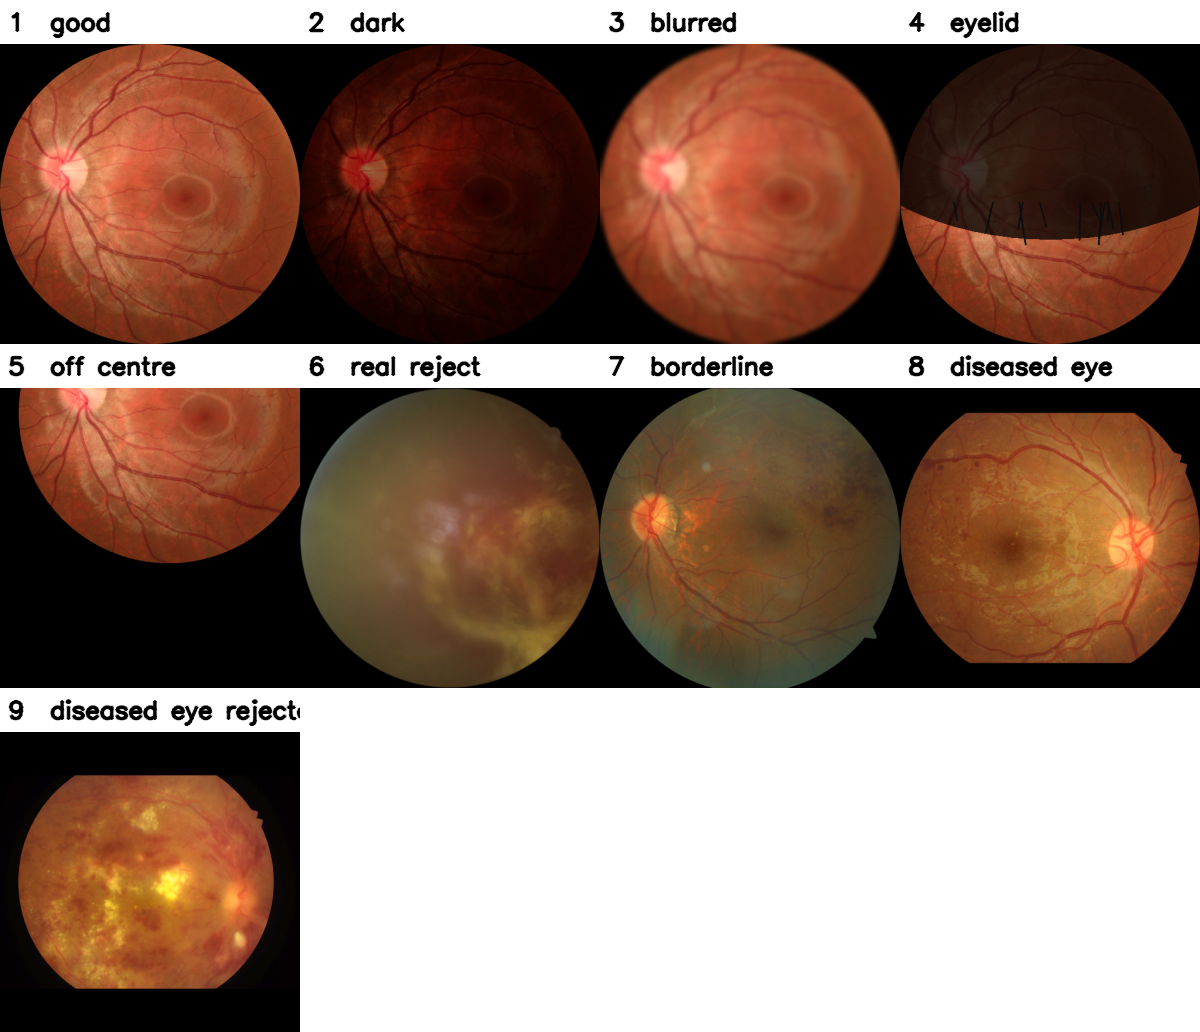

In [6]:
# ============================================================================
# CELL 6 - Build the pack, then run it exactly as the laptop will
# ============================================================================
REQUIREMENTS = """# What the screening laptop needs to run deploy/infer_offline.py. No TensorFlow.
ai-edge-litert==2.3.0      # the TensorFlow Lite interpreter (LiteRT). If it will not
                           # install on your platform, `pip install tensorflow` instead -
                           # the script falls back to TensorFlow's bundled interpreter.
opencv-python-headless>=4.8
numpy>=1.26
"""
WIN, MAC = r"venv\Scripts\python", "venv/bin/python"

PACK = WORK / "demo_pack"
if PACK.exists():
    shutil.rmtree(PACK)
(PACK / "photos").mkdir(parents=True)
(PACK / "extra").mkdir()
shutil.copy(WORK / "infer_offline.py", PACK / "infer_offline.py")
shutil.copy(MODEL, PACK / MODEL.name)
(PACK / "requirements-deploy.txt").write_text(REQUIREMENTS)

files = []
for i, p in enumerate(picks, 1):
    p["file"] = f"photos/{i}_{p['name']}.png"
    shutil.copy(p["path"], PACK / p["file"])
    files.append(p["file"])

# Edge cases, for questions only
(PACK / "extra" / "not_a_photo.txt").write_text("this is not an image\n")
cv2.imwrite(str(PACK / "extra" / "blank.png"), np.zeros((512, 512, 3), np.uint8))
cv2.imwrite(str(PACK / "extra" / "noise.png"),
            np.random.default_rng(0).integers(0, 256, (512, 512, 3), dtype=np.uint8))
cv2.imwrite(str(PACK / "extra" / "tiny.png"),
            cv2.resize(cv2.imread(str(picks[0]["path"])), (96, 96), interpolation=cv2.INTER_AREA))
extras = ["extra/not_a_photo.txt", "extra/blank.png", "extra/noise.png", "extra/tiny.png"]


def cli(args):
    """The command the operator types, run in the pack folder."""
    t0 = time.perf_counter()
    out = subprocess.run([sys.executable, "infer_offline.py", *args], cwd=PACK,
                         capture_output=True, text=True)
    if out.returncode != 0:
        raise RuntimeError(f"infer_offline.py failed:\n{out.stderr[-3000:]}")
    return out.stdout, time.perf_counter() - t0


demo_out, demo_secs = cli(files)
extra_out, _ = cli(extras)
print(demo_out)
print(extra_out)

lat = []
for _ in range(30):
    t0 = time.perf_counter()
    assessor.assess(PACK / files[0])
    lat.append(time.perf_counter() - t0)
LAT_MS = 1000 * float(np.median(lat))
print(f"one photograph (read, prepare, model): {LAT_MS:.0f} ms, median of 30 on Kaggle's CPU")
print(f"the whole command for {len(files)} photographs, start-up included: {demo_secs:.1f} s "
      "here. Time it again on the laptop - start-up differs from machine to machine.")

(PACK / "EXPECTED.txt").write_text(
    f"What infer_offline.py printed in Kaggle on {date.today()} (retina-09-demo-pack).\n"
    "On the laptop the verdicts and causes must be the same; a confidence or severity\n"
    "may differ in the last digit.\n\n"
    f"$ python infer_offline.py {' '.join(files)}\n{demo_out}\n"
    f"$ python infer_offline.py {' '.join(extras)}\n{extra_out}")

# Contact sheet: every demo photo with its number, to keep on screen beside the terminal
def tile(path, label, size=300):
    im = cv2.resize(cv2.imread(str(path)), (size, size), interpolation=cv2.INTER_AREA)
    bar = np.full((44, size, 3), 255, np.uint8)
    cv2.putText(bar, label, (8, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2, cv2.LINE_AA)
    return np.vstack([bar, im])


tiles = [tile(PACK / p["file"], f"{i}  {p['name'].replace('_', ' ')}")
         for i, p in enumerate(picks, 1)]
while len(tiles) % 4:
    tiles.append(np.full_like(tiles[0], 255))
cv2.imwrite(str(PACK / "contact_sheet.png"),
            np.vstack([np.hstack(tiles[i:i + 4]) for i in range(0, len(tiles), 4)]))

# README: set-up, the demo in order with what to say, and what to do if it goes wrong
SAY = {
    "good": "A good photo from a camera the model never saw in training. Good, no retake: the operator moves on.",
    "dark": "The same photo, darkened the way a small pupil or a weak flash darkens it. It names the cause and says what to check.",
    "blurred": "The same photo, out of focus. It names defocus and tells the operator to refocus.",
    "eyelid": "The same photo with an eyelid and lashes across the top. It names obstruction.",
    "off_centre": "The same photo, shifted off centre. It names the framing.",
    "real_reject": "A real photo that human graders called ungradable, from another camera the model never saw. It names {cause} as the likely cause.",
    "borderline": "A real photo graders called Usable. Gradable but borderline: retake only if the patient is still there.",
    "diseased_eye": "An eye with advanced retinopathy, photographed well. Good: the model does not mistake disease for a bad photo.",
    "diseased_eye_rejected": "A diseased eye the model does reject, but no camera fault stands out, so it says retake once and then send it to the grader. It never throws a photo away.",
}
COVERS = {
    "good": "three-level verdict; unseen camera",
    "dark": "names the cause; tells the operator what to do",
    "blurred": "names the cause; tells the operator what to do",
    "eyelid": "names the cause; tells the operator what to do",
    "off_centre": "names the cause; tells the operator what to do",
    "real_reject": "unseen camera; names the cause on a real photo",
    "borderline": "the middle level of the three-level verdict",
    "diseased_eye": "does not mistake disease for poor quality",
    "diseased_eye_rejected": "never discards a photo; doubtful cases go to the grader",
}

steps = []
for i, p in enumerate(picks, 1):
    x = p["result"]
    expect = f"{x['verdict']} ({x['conf']:.0%} confident)"
    if x["verdict"] != "Good":
        expect += f", most likely cause {x['cause']} ({x['sev']:.2f})"
        if x["sev"] < inf.PRESENT:
            expect += ": under 0.25, so the script reports no camera cause"
    cause = {"underexposed": "underexposure", "defocus": "blur",
             "obstruction": "an obstruction", "off_centre": "the framing"}[x["cause"]]
    steps.append(f"  {i}. {WIN} infer_offline.py {p['file']}\n"
                 f"     What it is:  {p['about']}\n"
                 f"     Expect:      {expect}\n"
                 f"     Say:         {SAY[p['name']].format(cause=cause)}\n"
                 f"     Covers:      {COVERS[p['name']]}\n")

README = f"""OFFLINE RETINAL GRADABILITY CHECK - DEMO PACK
Built in Kaggle by retina-09-demo-pack on {date.today()}. Before building it, the
script gave the validated model's verdict on {AGREE:.1%} of 400 external photographs.

WHAT IS HERE
  infer_offline.py                  the script (identical to deploy/infer_offline.py)
  {MODEL.name}   the model, {MODEL.stat().st_size / 1e6:.2f} MB. Keep it next to the script.
  requirements-deploy.txt           the three packages the laptop needs
  photos/                           demo photographs, numbered in demo order
  extra/                            edge cases, only if someone asks
  contact_sheet.png                 every demo photo with its number: keep it on screen
  EXPECTED.txt                      what the script printed for every photo in Kaggle

SET UP THE LAPTOP - once, with internet. Python 3.10 to 3.14.
A Windows laptop or an Apple-silicon Mac. An Intel Mac cannot install the interpreter.
Open a terminal in this folder, then:
  Windows:  python -m venv venv
            {WIN} -m pip install -r requirements-deploy.txt
            (if "python" is not found, type "py" instead)
  Mac:      python3 -m venv venv
            {MAC} -m pip install -r requirements-deploy.txt

CHECK IT - then switch the internet off and check again
  Windows:  {WIN} infer_offline.py photos/1_good.png
  Mac:      {MAC} infer_offline.py photos/1_good.png
  The line "INFO: Created TensorFlow Lite XNNPACK delegate for CPU." is normal.
  Run every photo once and compare with EXPECTED.txt.

THE DEMO - one command per photo. Windows shown; on a Mac type {MAC} instead of
{WIN}. Keep contact_sheet.png open beside the terminal.

{chr(10).join(steps)}
ALL AT ONCE - shows the speed
  {WIN} infer_offline.py {' '.join(files)}
  Wildcards such as photos/* do not work on Windows, so keep the files listed.

EDGE CASES - only if someone asks
  {WIN} infer_offline.py {' '.join(extras)}
  A file that is not an image gets "cannot read image" instead of a crash. The model
  was not built to recognise things that are not retinal photographs, so it still
  gives a verdict for a blank or noise image (EXPECTED.txt shows what it says).

IF SOMETHING GOES WRONG
  "No module named ..."           the install did not finish: rerun it with internet on
  "... not found - download it"   the .tflite file is not next to infer_offline.py
  "cannot read image"             a typo in the file name: check it and rerun
  anything else                   play the backup screen recording
"""
(PACK / "README.txt").write_text(README)

shutil.rmtree(STAGE)                                   # candidate images, no longer needed
ZIP = WORK / "demo_pack.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(PACK.rglob("*")):
        z.write(f, f.relative_to(WORK))

try:
    from IPython.display import Image, display
    display(Image(filename=str(PACK / "contact_sheet.png"), width=900))
except ImportError:
    pass

In [7]:
# ============================================================================
# CELL 7 - Outputs
# ============================================================================
print("demo_pack/")
for f in sorted(PACK.rglob("*")):
    if f.is_file():
        print(f"   {str(f.relative_to(PACK)):42s} {f.stat().st_size / 1e6:6.2f} MB")
print(f"\ndemo_pack.zip   {ZIP.stat().st_size / 1e6:.1f} MB   <- download this one file")
print(f"\nscript agreement   {AGREE:.1%} of 400 photographs (the notebook stops below {MIN_AGREEMENT:.0%})")
print(f"demo photographs   {len(picks)}")
print(f"skipped            {'; '.join(SKIPPED) if SKIPPED else 'none'}")
print(f"speed on Kaggle    {LAT_MS:.0f} ms per photograph")

demo_pack/
   EXPECTED.txt                                 0.00 MB
   README.txt                                   0.01 MB
   contact_sheet.png                            0.85 MB
   extra/blank.png                              0.00 MB
   extra/noise.png                              0.79 MB
   extra/not_a_photo.txt                        0.00 MB
   extra/tiny.png                               0.01 MB
   infer_offline.py                             0.01 MB
   photos/1_good.png                            0.31 MB
   photos/2_dark.png                            0.22 MB
   photos/3_blurred.png                         0.20 MB
   photos/4_eyelid.png                          0.23 MB
   photos/5_off_centre.png                      0.18 MB
   photos/6_real_reject.png                     0.23 MB
   photos/7_borderline.png                      0.28 MB
   photos/8_diseased_eye.png                    0.28 MB
   photos/9_diseased_eye_rejected.png           0.23 MB
   requirements-deploy.txt           

## AFTER IT RUNS

1. From the version's **Output** tab, download `demo_pack.zip` for the laptop.
2. Download this executed notebook and save it as `notebooks/retina-09-demo-pack.ipynb` (commit 12 in the guide).
3. Copy the `same verdict` percentage from cell 4 into Section 5.9 of the report.
4. Look at the contact sheet under cell 6 and at any `SKIPPED` lines under cell 5. A skipped photo only means one step fewer in the demo.
5. On the demo laptop, follow `README.txt` inside the pack.